# Project : An OpenMP-based parallel implementation of image enhancement technique for dark images
# Batuhan Hangun1 · Salih Bayar2
Received: 2 September 2023 / Revised: 4 January 2024 / Accepted: 30 January 2024 / Published online: 4 March 2024
© The Author(s), under exclusive licence to Springer-Verlag London Ltd., part of Springer Nature 2024

#1) Install Required Libraries and Check Environment Setup

In [4]:
!apt-get -qq update
!apt-get -qq install -y g++
!pip -q install opencv-python-headless matplotlib numpy
import os, cv2, numpy as np, matplotlib.pyplot as plt, pandas as pd, subprocess, time
print(subprocess.check_output(["g++", "--version"], text=True).splitlines()[0])
print("OpenCV:", cv2.__version__)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
OpenCV: 4.14.0


## 2) Upload an image

Saving istockphoto-1358221035-612x612.jpg to istockphoto-1358221035-612x612 (1).jpg
Input shape: (344, 612, 3)


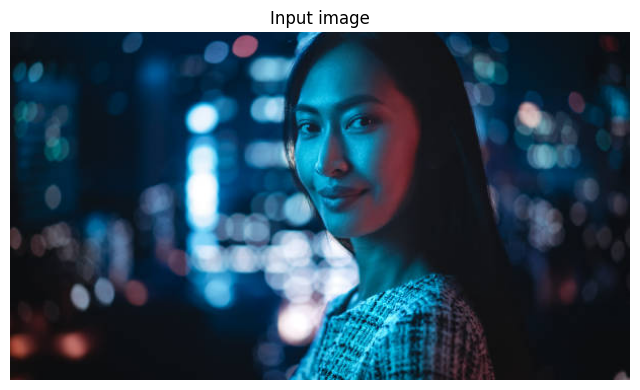

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
uploaded = files.upload()
if uploaded:
    image_path = next(iter(uploaded))
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise ValueError("Could not read uploaded image. Please upload JPG/PNG.")
else:
    # Built-in illustrative image: gradients + shapes, intentionally darkened
    h, w = 720, 960
    y, x = np.mgrid[0:h, 0:w]
    base = np.zeros((h,w,3), np.uint8)
    base[:,:,0] = np.clip(35 + 55*x/w + 20*np.sin(y/35),0,255)
    base[:,:,1] = np.clip(45 + 70*y/h + 18*np.sin(x/45),0,255)
    base[:,:,2] = np.clip(65 + 90*(1-x/w) + 15*np.cos(y/40),0,255)
    cv2.circle(base,(w//3,h//2),110,(70,130,190),-1)
    cv2.rectangle(base,(w//2, h//3),(w-100, h-100),(95,145,180),-1)
    cv2.line(base,(40,h-90),(w-40,80),(180,190,200),8)
    img_bgr = (base.astype(np.float32)*0.32).clip(0,255).astype(np.uint8)
    image_path = "built_in_dark_demo.png"
print("Input shape:", img_bgr.shape)
plt.figure(figsize=(8,5)); plt.imshow(cv2.cvtColor(img_bgr,cv2.COLOR_BGR2RGB)); plt.title("Input image"); plt.axis("off"); plt.show()

## 3) Compile the C++ OpenMP Kernel
The same C++ routine is used in sequential mode (`parallel_mode=0`) and OpenMP mode (`parallel_mode=1`), enabling a fair comparison.

In [11]:
%%writefile enhancement.cpp
#include <omp.h>
#include <algorithm>
#include <cmath>
#include <cstdint>
#include <vector>
extern "C" {
void enhance_v(const uint8_t* input, uint8_t* output, int h, int w, int threads, int parallel_mode) {
    const int n=h*w;
    std::vector<float> blur(n,0.0f), mask(n,0.0f), sharp(n,0.0f);
    const int k[5]={1,4,6,4,1}; // separable 5x5 Gaussian weights; sum=256
    if(parallel_mode) omp_set_num_threads(threads);
    // Local stage: Gaussian blur
    #pragma omp parallel for if(parallel_mode) schedule(static)
    for(int y=0;y<h;y++) for(int x=0;x<w;x++){
        float sum=0.0f;
        for(int dy=-2;dy<=2;dy++) for(int dx=-2;dx<=2;dx++){
            int yy=std::min(h-1,std::max(0,y+dy));
            int xx=std::min(w-1,std::max(0,x+dx));
            sum += input[yy*w+xx] * k[dy+2] * k[dx+2];
        }
        blur[y*w+x]=sum/256.0f;
    }
    // Mask and unsharp sharpening: S = I + 1.2 * max(I - blur, 0)
    #pragma omp parallel for if(parallel_mode) schedule(static)
    for(int i=0;i<n;i++) mask[i]=std::max(0.0f,(float)input[i]-blur[i]);
    #pragma omp parallel for if(parallel_mode) schedule(static)
    for(int i=0;i<n;i++) sharp[i]=std::min(255.0f,std::max(0.0f,input[i]+1.2f*mask[i]));
    // Histogram: private per-thread bins avoid data races, then merge.
    int actual_threads = parallel_mode ? threads : 1;
    std::vector<unsigned long long> hist((size_t)actual_threads*256,0);
    #pragma omp parallel if(parallel_mode) num_threads(threads)
    {
        int tid=parallel_mode ? omp_get_thread_num() : 0;
        unsigned long long* local=&hist[(size_t)tid*256];
        #pragma omp for schedule(static)
        for(int i=0;i<n;i++) local[(int)sharp[i]]++;
    }
    unsigned long long total[256]={0};
    for(int t=0;t<actual_threads;t++) for(int b=0;b<256;b++) total[b]+=hist[(size_t)t*256+b];
    unsigned long long cdf[256]={0}, c=0;
    for(int b=0;b<256;b++){ c+=total[b]; cdf[b]=c; }
    unsigned long long cdf_min=0;
    for(int b=0;b<256;b++) if(total[b]) { cdf_min=cdf[b]; break; }
    unsigned long long denom=(unsigned long long)n-cdf_min;
    uint8_t lut[256];
    for(int b=0;b<256;b++){
        if(denom==0) lut[b]=(uint8_t)b;
        else {
            double z=(double)(cdf[b]-std::min(cdf[b],cdf_min))*255.0/(double)denom;
            lut[b]=(uint8_t)std::min(255.0,std::max(0.0,std::round(z)));
        }
    }
    #pragma omp parallel for if(parallel_mode) schedule(static)
    for(int i=0;i<n;i++) output[i]=lut[(int)sharp[i]];
}
}

Overwriting enhancement.cpp


In [12]:
!g++ -O3 -shared -fPIC -fopenmp enhancement.cpp -o libenhance.so
import ctypes
lib = ctypes.CDLL("./libenhance.so")
fn = lib.enhance_v
fn.argtypes = [ctypes.POINTER(ctypes.c_uint8), ctypes.POINTER(ctypes.c_uint8),
               ctypes.c_int, ctypes.c_int, ctypes.c_int, ctypes.c_int]
fn.restype = None
print("Compiled OpenMP shared library successfully.")

Compiled OpenMP shared library successfully.


# 4) Run Image Enhancement and Visualize The Result


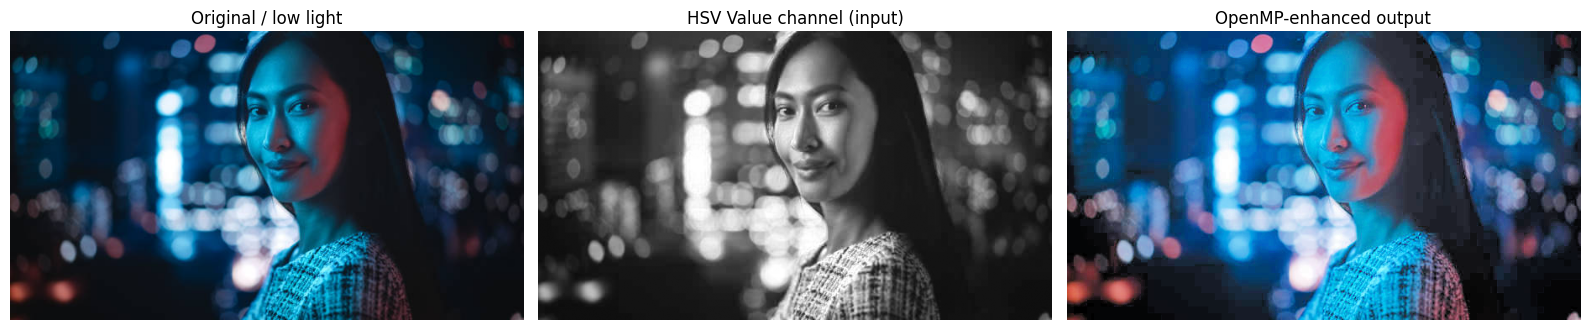

Saved enhanced_output.png


In [13]:
def run_kernel(v_channel, threads=4, parallel=True):
    v = np.ascontiguousarray(v_channel, dtype=np.uint8)
    out = np.empty_like(v)
    h, w = v.shape
    fn(v.ctypes.data_as(ctypes.POINTER(ctypes.c_uint8)),
       out.ctypes.data_as(ctypes.POINTER(ctypes.c_uint8)),
       h, w, int(threads), int(parallel))
    return out

hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
v_in = hsv[:,:,2]
v_out = run_kernel(v_in, threads=4, parallel=True)
hsv_out = hsv.copy(); hsv_out[:,:,2] = v_out
enhanced_bgr = cv2.cvtColor(hsv_out, cv2.COLOR_HSV2BGR)

fig, ax = plt.subplots(1,3,figsize=(16,5))
ax[0].imshow(cv2.cvtColor(img_bgr,cv2.COLOR_BGR2RGB)); ax[0].set_title("Original / low light")
ax[1].imshow(v_in,cmap="gray",vmin=0,vmax=255); ax[1].set_title("HSV Value channel (input)")
ax[2].imshow(cv2.cvtColor(enhanced_bgr,cv2.COLOR_BGR2RGB)); ax[2].set_title("OpenMP-enhanced output")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
cv2.imwrite("enhanced_output.png", enhanced_bgr)
print("Saved enhanced_output.png")



# 5) Speedup Analysis

Threads,Serial time,Parallel time,Speedup
1,0.01188 s,0.00940 s,1.26x
2,0.01188 s,0.00973 s,1.22x
4,0.01188 s,0.00980 s,1.21x


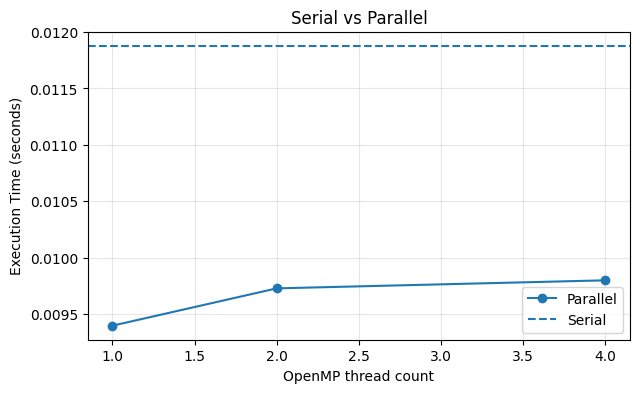

In [17]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

def timed_run(v, threads=4, parallel=True, repeats=5):
    samples=[]
    for _ in range(repeats):
        t0=time.perf_counter()
        run_kernel(v, threads=threads, parallel=parallel)
        samples.append(time.perf_counter()-t0)
    return float(np.median(samples))

# Warm-up
run_kernel(v_in, 1, False); run_kernel(v_in, 4, True)
max_threads = max(1, min(8, os.cpu_count() or 2))
thread_counts = sorted(set([1, 2, 4, max_threads]))
seq_time = timed_run(v_in, threads=1, parallel=False, repeats=5)
rows=[]
for t in thread_counts:
    par_time = timed_run(v_in, threads=t, parallel=True, repeats=5)
    rows.append({"Threads": t, "Serial time": seq_time,
                 "Parallel time": par_time, "Speedup": seq_time/par_time})
results = pd.DataFrame(rows).drop_duplicates("Threads").sort_values("Threads")

# Enhanced styling: hide index entirely to keep all 4 headers in one row
styled_results = (results.style
                  .hide(axis="index")
                  .format({
                      "Threads": "{:d}",
                      "Serial time": "{:.5f} s",
                      "Parallel time": "{:.5f} s",
                      "Speedup": "{:.2f}x"
                  })
                  .background_gradient(cmap="Blues", subset=["Speedup"])
                  .set_properties(**{
                      'text-align': 'center',
                      'white-space': 'nowrap'
                  })
                  .set_table_styles([
                      {
                          'selector': 'th',
                          'props': [
                              ('text-align', 'center'),
                              ('font-weight', 'bold'),
                              ('white-space', 'nowrap')
                          ]
                      }
                  ]))

display(HTML(styled_results.to_html()))

plt.figure(figsize=(7,4))
plt.plot(results["Threads"], results["Parallel time"], marker="o", label="Parallel")
plt.axhline(seq_time, linestyle="--", label="Serial")
plt.xlabel("OpenMP thread count"); plt.ylabel("Execution Time (seconds)")
plt.title("Serial vs Parallel"); plt.grid(True,alpha=.3); plt.legend()
plt.show()


**Interpretation and Conclusion**
- **Local Enhancement :** Gaussian blur is subtracted from the value channel to form a detail mask; the mask is added back for sharpening.
- **Global Enhancement :** Histogram equalization stretches the value distribution to improve image contrast.
- **Parallelism :** Independent pixel loops use `#pragma omp parallel for` to process multiple pixels simultaneously; histogram counting uses per-thread bins to avoid race conditions.
- **Metrics :** speedup = sequential time / parallel time. Speedup above 1 means the parallel run was faster.

### Reference
Hangun, B. & Bayar, S. (2024). *An OpenMP-based parallel implementation of image enhancement technique for dark images*. Signal, Image and Video Processing, 18, 4115–4130. https://doi.org/10.1007/s11760-024-03058-8